## 논리연산(논리게이트) 학습 예시

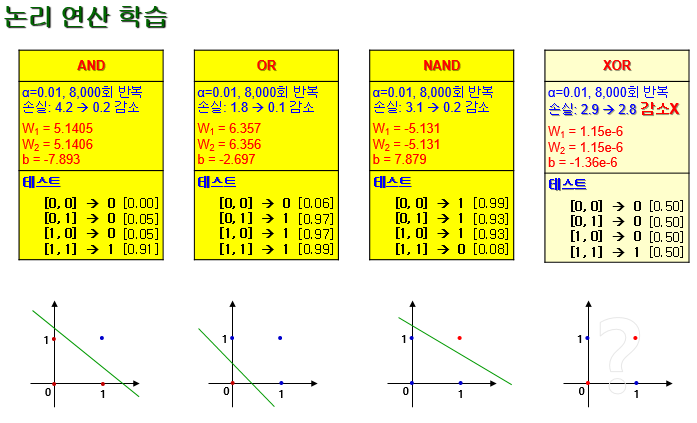

In [7]:
import numpy as np

def sigmoid(x):          # sigmoid 함수
    return 1 / (1+np.exp(-x))

def cross_entropy(t, y) : # 크로스 엔트로피 함수
    delta = 1e-7         # log 무한대 발산 방지
    return -np.sum(t*np.log(y+delta) + (1-t)*np.log((1-y)+delta))

def numerical_derivative(f, x):  # 수치미분 함수
    delta_x = 1e-4 # 0.0001
    grad = np.zeros_like(x)

    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        idx = it.multi_index
        temp = x[idx]
        x[idx] = temp + delta_x
        fx1 = f(x) # f(x+delta_x)

        x[idx] = temp - delta_x
        fx2 = f(x) # f(x-delta_x)
        grad[idx] = (fx1 - fx2) / (2*delta_x)

        x[idx] = temp
        it.iternext()
    return grad

class LogicGate:   # LogicGate Class
    def __init__(self, gate_name, xdata, tdata):  # xdata, tdata => numpy.array(...)
        self.name = gate_name
        rows, cols = len(xdata), len(xdata[0])
        self.__xdata = xdata.reshape(rows,cols)   # 입력 데이터, 정답 데이터 초기화
        self.__tdata = tdata.reshape(rows,1)
        # 가중치 W, 바이어스 b 초기화
        self.__W = np.random.rand(cols,1)  # Weight, 2 X 1 matrix
        self.__b = np.random.rand(1)
        # 학습률 learning rate 초기화
        self.__learning_rate = 1e-2
        print(self.name, "object is created")

    def errFunc(self):    # 손실함수
        delta = 1e-7    # log함수의 - 무한대 발산 방지
        z = np.dot(self.__xdata, self.__W) + self.__b
        y = sigmoid(z)
        return cross_entropy(self.__tdata, y)

    def errValue(self):     # 손실 값 계산
        return  self.errFunc()

    def train(self, repeat=8000, outStep=1000):    # 수치미분을 이용하여 손실함수가 최소가 될때 까지 학습하는 함수
        f = lambda x : self.errFunc()

        print("Initial error value = ", self.errValue())
        for step in  range(repeat+1):
            self.__W -= self.__learning_rate * numerical_derivative(f, self.__W)
            self.__b -= self.__learning_rate * numerical_derivative(f, self.__b)
            if (step % outStep == 0):
                print("Step = {:<5d}\tError Val = {:.4f}\tW = {}".format(step, self.errValue(), self.__W.flatten().round(2)))


    def params(self):       # 파라미터(W, b) 출력
        print("Weights:", self.__W.flatten().round(2))
        print("Bias:", self.__b)

    def predict(self, input_data):     # 임의 입력에 대한 출력 함수
        z = np.dot(input_data, self.__W) + self.__b
        y = sigmoid(z)
        return y

In [8]:
# AND Gate prediction
xdata = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
tdata = np.array([0, 0, 0, 1])

AND_obj = LogicGate("AND_GATE", xdata, tdata)
AND_obj.train()
AND_obj.params()

AND_GATE object is created
Initial error value =  3.42417118143703
Step = 0    	Error Val = 3.3915	W = [0.54 0.28]
Step = 1000 	Error Val = 1.0160	W = [1.81 1.78]
Step = 2000 	Error Val = 0.6640	W = [2.73 2.72]
Step = 3000 	Error Val = 0.4935	W = [3.36 3.36]
Step = 4000 	Error Val = 0.3916	W = [3.85 3.85]
Step = 5000 	Error Val = 0.3238	W = [4.25 4.25]
Step = 6000 	Error Val = 0.2756	W = [4.59 4.59]
Step = 7000 	Error Val = 0.2395	W = [4.89 4.89]
Step = 8000 	Error Val = 0.2117	W = [5.14 5.14]
Weights: [5.14 5.14]
Bias: [-7.89599747]


In [9]:
print("===", AND_obj.name, "testing ....")
test_data = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
for test in test_data:
    y = AND_obj.predict(test)
    print(test, " = ", int(y>0.5), " [%.4f]"%y)

=== AND_GATE testing ....
[0 0]  =  0  [0.0004]
[0 1]  =  0  [0.0599]
[1 0]  =  0  [0.0599]
[1 1]  =  1  [0.9159]


In [10]:
# OR Gate prediction
xdata = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
tdata = np.array([0, 1, 1, 1])

OR_obj = LogicGate("OR_GATE", xdata, tdata)
OR_obj.train()
OR_obj.params()

OR_GATE object is created
Initial error value =  1.8493558162973731
Step = 0    	Error Val = 1.8462	W = [0.49 0.39]
Step = 1000 	Error Val = 0.7238	W = [2.53 2.51]
Step = 2000 	Error Val = 0.4334	W = [3.62 3.61]
Step = 3000 	Error Val = 0.3046	W = [4.37 4.36]
Step = 4000 	Error Val = 0.2332	W = [4.92 4.92]
Step = 5000 	Error Val = 0.1882	W = [5.37 5.37]
Step = 6000 	Error Val = 0.1574	W = [5.73 5.73]
Step = 7000 	Error Val = 0.1351	W = [6.05 6.05]
Step = 8000 	Error Val = 0.1182	W = [6.32 6.32]
Weights: [6.32 6.32]
Bias: [-2.67897902]


In [11]:
print("===", OR_obj.name, "testing ...")
test_data = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
for test in test_data:
    y = OR_obj.predict(test)
    print(test, " = ", int(y>0.5), " [%.4f]"%y)

=== OR_GATE testing ...
[0 0]  =  0  [0.0642]
[0 1]  =  1  [0.9744]
[1 0]  =  1  [0.9745]
[1 1]  =  1  [1.0000]


In [12]:
# NAND Gate prediction
xdata = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
tdata = np.array([1, 1, 1, 0])

NAND_obj = LogicGate("NAND_GATE", xdata, tdata)
NAND_obj.train()
NAND_obj.params()

NAND_GATE object is created
Initial error value =  2.527199360629745
Step = 0    	Error Val = 2.5206	W = [ 0.49 -0.  ]
Step = 1000 	Error Val = 1.0058	W = [-1.79 -1.85]
Step = 2000 	Error Val = 0.6597	W = [-2.73 -2.74]
Step = 3000 	Error Val = 0.4911	W = [-3.37 -3.37]
Step = 4000 	Error Val = 0.3901	W = [-3.86 -3.86]
Step = 5000 	Error Val = 0.3228	W = [-4.26 -4.26]
Step = 6000 	Error Val = 0.2748	W = [-4.6 -4.6]
Step = 7000 	Error Val = 0.2390	W = [-4.89 -4.89]
Step = 8000 	Error Val = 0.2112	W = [-5.15 -5.15]
Weights: [-5.15 -5.15]
Bias: [7.90287005]


In [13]:
print("===", NAND_obj.name, "testing ...")
test_data = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
for test in test_data:
    y = NAND_obj.predict(test)
    print(test, " = ", int(y>0.5), " [%.4f]"%y)

=== NAND_GATE testing ...
[0 0]  =  1  [0.9996]
[0 1]  =  1  [0.9403]
[1 0]  =  1  [0.9403]
[1 1]  =  0  [0.0839]


In [14]:
# XOR Gate prediction => 예측이 되지 않음
# XOR Gate 를 보면, 손실함수 값이 2.7 근처에서 더 이상 감소하지 않는것을 볼수 있음
xdata = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
tdata = np.array([0, 1, 1, 0])

XOR_obj = LogicGate("XOR_GATE", xdata, tdata)
XOR_obj.train()
XOR_obj.params()

XOR_GATE object is created
Initial error value =  3.834048459750381
Step = 0    	Error Val = 3.8101	W = [0.91 0.63]
Step = 1000 	Error Val = 2.7732	W = [0.06 0.04]
Step = 2000 	Error Val = 2.7726	W = [0.01 0.01]
Step = 3000 	Error Val = 2.7726	W = [0. 0.]
Step = 4000 	Error Val = 2.7726	W = [0. 0.]
Step = 5000 	Error Val = 2.7726	W = [0. 0.]
Step = 6000 	Error Val = 2.7726	W = [0. 0.]
Step = 7000 	Error Val = 2.7726	W = [0. 0.]
Step = 8000 	Error Val = 2.7726	W = [0. 0.]
Weights: [0. 0.]
Bias: [-9.19719297e-07]


In [15]:
print("===", XOR_obj.name, "testing ... ")
test_data = np.array([ [0, 0], [0, 1], [1, 0], [1, 1] ])
for test in test_data:
    y = XOR_obj.predict(test)
    print(test, " = ", int(y>0.5), " [%.4f]"%y)

=== XOR_GATE testing ... 
[0 0]  =  0  [0.5000]
[0 1]  =  0  [0.5000]
[1 0]  =  0  [0.5000]
[1 1]  =  1  [0.5000]


In [16]:
# XOR 3-in gate
xdata = np.array([ [0,0,0], [0,0,1], [0,1,0], [0,1,1],[1,0,0], [1,0,1], [1,1,0], [1,1,1] ])
tdata = np.array([0, 1, 1, 0, 1, 0, 0, 1])

XOR3_obj = LogicGate("XOR_3-in_GATE", xdata, tdata)
XOR3_obj.train()
XOR3_obj.params()

XOR_3-in_GATE object is created
Initial error value =  7.326299321665116
Step = 0    	Error Val = 7.2311	W = [0.04 0.74 0.72]
Step = 1000 	Error Val = 5.5452	W = [0.   0.01 0.01]
Step = 2000 	Error Val = 5.5452	W = [0. 0. 0.]
Step = 3000 	Error Val = 5.5452	W = [0. 0. 0.]
Step = 4000 	Error Val = 5.5452	W = [0. 0. 0.]
Step = 5000 	Error Val = 5.5452	W = [0. 0. 0.]
Step = 6000 	Error Val = 5.5452	W = [0. 0. 0.]
Step = 7000 	Error Val = 5.5452	W = [0. 0. 0.]
Step = 8000 	Error Val = 5.5452	W = [0. 0. 0.]
Weights: [0. 0. 0.]
Bias: [-6.76129153e-11]


In [17]:
print("===", XOR3_obj.name, "testing ... ")
test_data = np.array([ [0,0,0], [0,0,1], [0,1,0], [0,1,1],[1,0,0], [1,0,1], [1,1,0], [1,1,1] ])
for test in test_data:
    y = XOR3_obj.predict(test)
    print(test, " = ", int(y>0.5), " [%.4f]"%y)

=== XOR_3-in_GATE testing ... 
[0 0 0]  =  0  [0.5000]
[0 0 1]  =  0  [0.5000]
[0 1 0]  =  0  [0.5000]
[0 1 1]  =  1  [0.5000]
[1 0 0]  =  0  [0.5000]
[1 0 1]  =  1  [0.5000]
[1 1 0]  =  1  [0.5000]
[1 1 1]  =  1  [0.5000]
